# Deconvolving AIA images with the instrument Point Spread Function (PSF)

(based on `https://aiapy.readthedocs.io/en/stable/generated/gallery/psf_deconvolution.html`)

This example demonstrates how to deconvolve an AIA image with the instrument point spread function (PSF).

First, we’ll use a single level 1 image from the 171 Å channel from 10 September 2017. Note that deconvolution should be performed on level 1 images only. This is because, as with the level 1 data, the PSF model is defined on the CCD grid.

The PSF model accounts for several different effects, including diffraction from the mesh grating of the filters, charge spreading, and jitter. See Grigis et al (2012) for more details. Currently, this only works for 4096 ×4096 full frame images.

This Point Spread Function is that developed initially by the AIA Team. In total there are 3 known PSF Variants:
1. (P. Grigis et al. 2012) : (this notebook) developed by the AIA Team. 
2. (B. Poduval et al. 2013) : Untested
3. (Hofmeister et al. 2025) : Untested

## Objectives: 

1. Understand the **File Size Implications** of deconvolving images.
    - The AIA Dataset is _huge_ and we want to try to be as efficient as possible. 
2. Understand the **Time Complexity Requirements** of deconvolving images
    - Is this possible to operationalize as a correction for _live_ AIA data? 

Side Quests:
- Is this stable across the different AIA Wavelengths? 
- Is this stable across both "quiet" solar times and solar flare times? 

## Calculating the PSF

See https://sohoftp.nascom.nasa.gov/solarsoft/sdo/aia/idl/psf/DOC/psfreport.pdf for more information about calculating the PSF.

Calculating the PSF is noted to be faster with the `jax` library (https://docs.jax.dev/en/latest/installation.html)

> JAX is a Python library for accelerator-oriented array computation and program transformation, designed for high-performance numerical computing and large-scale machine learning.

The table below shows all supported platforms and installation options. Check if your setup is supported; and if it says _"yes"_ or _"experimental"_, then click on the corresponding link to learn how to install JAX in greater detail.

|                  | Linux, x86_64 | Linux, aarch64 | Mac, aarch64   | Windows, x86_64 | Windows WSL2, x86_64   |
|------------------|---------------|----------------|----------------|-----------------|------------------------|
| CPU              | `yes`         | `yes `         | `yes `         | `yes `          | `yes `                 |
| NVIDIA GPU       | `yes`         | `yes`          | n/a            | no              | `experimental`.        |
| Google Cloud TPU | `yes`         | n/a            | n/a            | n/a             | n/a                    |
| AMD GPU          | `yes`         | no             | n/a            | no              | `experimental`         |
| Apple GPU        | n/a           | no             | `experimental` | n/a             | n/a                    |
| Intel GPU        | `experimental`| n/a            | n/a            | no              | no                     |

**NOTE:** Although referenced as experimental, Jax does not have any easily-found documentation for how it can be configured for MAC `aarch64` GPU systems. 

## De-Convolving the Image with the PSF

This is based on the Richardson-Lucy deconvolution algorithm: https://en.wikipedia.org/wiki/Richardson%E2%80%93Lucy_deconvolution

**NOTE:** that passing in the PSF is optional. If you exclude it, it will be calculated automatically. However, when deconvolving many images of the same wavelength, it is most efficient to only calculate the PSF once.

As with `aiapy.psf.calculate_psf`, this will be much faster if you have a Nvidia GPU and `cupy` installed: https://docs.cupy.dev/en/stable/index.html#module-cupy

**NOTE:** Again, this is not supported on MAC GPUs. This requires NVIDIA GPU with CUDA 12+, NumPy 2.0+.



In [1]:
import os
from pathlib import Path

import aiapy.psf
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
import sunpy.map
from astropy.coordinates import SkyCoord
from astropy.io import fits
from matplotlib import colors
from sunpy.net import Fido
from sunpy.net import attrs as a
from sunpy.time import parse_time

/opt/miniconda3/envs/swxsoc/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Search for Relevant AIA Data
t_start = parse_time("2017-09-10T20:00:00")
search_results = Fido.search(
    a.Time(t_start, t_start + 12 * u.s),
    a.Instrument.aia,
    a.Wavelength(171 * u.angstrom),
)
search_results

Start Time,End Time,Source,Instrument,Wavelength,Provider,Physobs,Wavetype,Extent Width,Extent Length,Extent Type,Size
,,,,Angstrom,,,,,,,Mibyte
Time,Time,str3,str3,float64[2],str4,str9,str6,str4,str4,str8,float64
2017-09-10 20:00:09.000,2017-09-10 20:00:10.000,SDO,AIA,171.0 .. 171.0,JSOC,intensity,NARROW,4096,4096,FULLDISK,64.64844


In [3]:
# Load the DATA_DIR Environment Variable
data_dir = Path(os.environ.get("DATA_DIR", "./data"))
print(f"Using DATA_DIR: {data_dir}")

Using DATA_DIR: /Users/arobbert/__SOC_CODE__/SDAC/data


In [4]:
# Set a directory to download the Test Files
local_test_files_dir = data_dir / "test_files"

files = Fido.fetch(search_results, path=local_test_files_dir, site="NSO")
files

Files Downloaded: 100%|██████████| 1/1 [00:01<00:00,  1.07s/file]


['/Users/arobbert/__SOC_CODE__/SDAC/data/test_files/aia.lev1.171A_2017_09_10T20_00_09.35Z.image_lev1.fits']

In [5]:
# Analyze the Original L1 AIA File Size
sizes = [Path(f).stat().st_size for f in files]
# Mean size of the original L1 AIA files
print(
    f"Mean size of the original L1 AIA files: {sum(sizes) / len(sizes) / 1024**2:.2f} MB"
)

Mean size of the original L1 AIA files: 11.13 MB


In [6]:
# Load the Data with Astropy IO
hdul = fits.open(files[0])

In [7]:
hdul.info()

Filename: /Users/arobbert/__SOC_CODE__/SDAC/data/test_files/aia.lev1.171A_2017_09_10T20_00_09.35Z.image_lev1.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   ()      
  1  COMPRESSED_IMAGE    1 CompImageHDU    187   (4096, 4096)   int16   


In [8]:
hdul[1].data.dtype

# Interesting the data type here is float32, which is different from the int16 in the `hdul.info()` output.
# This is because the data is stored in a compressed format in the FITS file, and when it is read into memory,
# it is converted to a different data type for processing.
# The `hdul.info()` output shows the data type of the compressed data on disk, while `hdul[1].data.dtype`
# shows the data type of the uncompressed data in memory.

dtype('float32')

In [9]:
# Load the FITS file to a SunPy map
aia_map = sunpy.map.Map(files[0])

In [10]:
# Look at the Data Type of the AIA Map
print(f"Data type of the AIA map: {aia_map.data.dtype}")

Data type of the AIA map: float32


In [11]:
# Primary Header Information
print(f"Primary Header Information: \n{aia_map.meta}")

Primary Header Information: 
('xtension': 'IMAGE')
('bitpix': '16')
('naxis': '2')
('naxis1': '4096')
('naxis2': '4096')
('pcount': '0')
('gcount': '1')
('bld_vers': 'V9R1X')
('lvl_num': '1.0')
('t_rec': '2017-09-10T20:00:10Z')
('trecstep': '1.0')
('trecepoc': '1977.01.01_00:00:00_TAI')
('trecroun': '1')
('origin': 'SDO/JSOC-SDP')
('date': '2017-09-14T08:38:31')
('telescop': 'SDO/AIA')
('instrume': 'AIA_3')
('date-obs': '2017-09-10T20:00:09.35')
('t_obs': '2017-09-10T20:00:10.35Z')
('camera': '3')
('img_type': 'LIGHT')
('exptime': '2.000169')
('expsdev': '0.000127')
('int_time': '2.273438')
('wavelnth': '171')
('waveunit': 'angstrom')
('wave_str': '171_THIN')
('fsn': '157960453')
('fid': '0')
('quallev0': '0')
('quality': '0')
('totvals': '16777216')
('datavals': '16777216')
('missvals': '0')
('percentd': '100.0')
('datamin': '-6')
('datamax': '16383')
('datamedn': '114')
('datamean': '155.57')
('datarms': '234.21')
('dataskew': '11.58')
('datakurt': '413.45')
('datacent': '139.36')
('

In [12]:
import jax

# NOTE: We justhave a single CPU device on this machine, so we don't need to specify a device.
jax.devices()

2026-09-04 10:52:48 - jax._src.xla_bridge - INFO: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/opt/miniconda3/envs/swxsoc/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache), 'libtpu.so' (no such file)


[CpuDevice(id=0)]

In [13]:
# Calculate the PSF For each available wavelength
valid_channels = [94, 131, 171, 193, 211, 304, 335] * u.angstrom

# Dict[wavelength, PSF] for each valid channel where PSF is an 4096x4096 np.ndarray
wavelength_psfs = {
    wavelength: aiapy.psf.calculate_psf(wavelength) for wavelength in valid_channels
}

In [14]:
# Save the PSFs for each Wavelength to the data directory
psf_dir = data_dir / "psfs"
grigis_2012 = psf_dir / "grigis_2012"
grigis_2012.mkdir(parents=True, exist_ok=True)
# Loop each wavelength and save the corresponding PSF to a file
for wavelength, psf in wavelength_psfs.items():
    psf_file = grigis_2012 / f"psf_{wavelength.value}.npy"
    # Save as np.ndarray for simplicity
    np.save(psf_file, psf, allow_pickle=False)

In [15]:
# Get the Min and Max Values of the PSFs for Normalization
psf_min = min(psf.min() for psf in wavelength_psfs.values())
psf_max = max(psf.max() for psf in wavelength_psfs.values())
# Print the Min and Max Values of the PSFs
print(f"Min value of the PSFs: {psf_min}")
print(f"Max value of the PSFs: {psf_max}")

Min value of the PSFs: 8.404588747503099e-25
Max value of the PSFs: 0.67627115958213


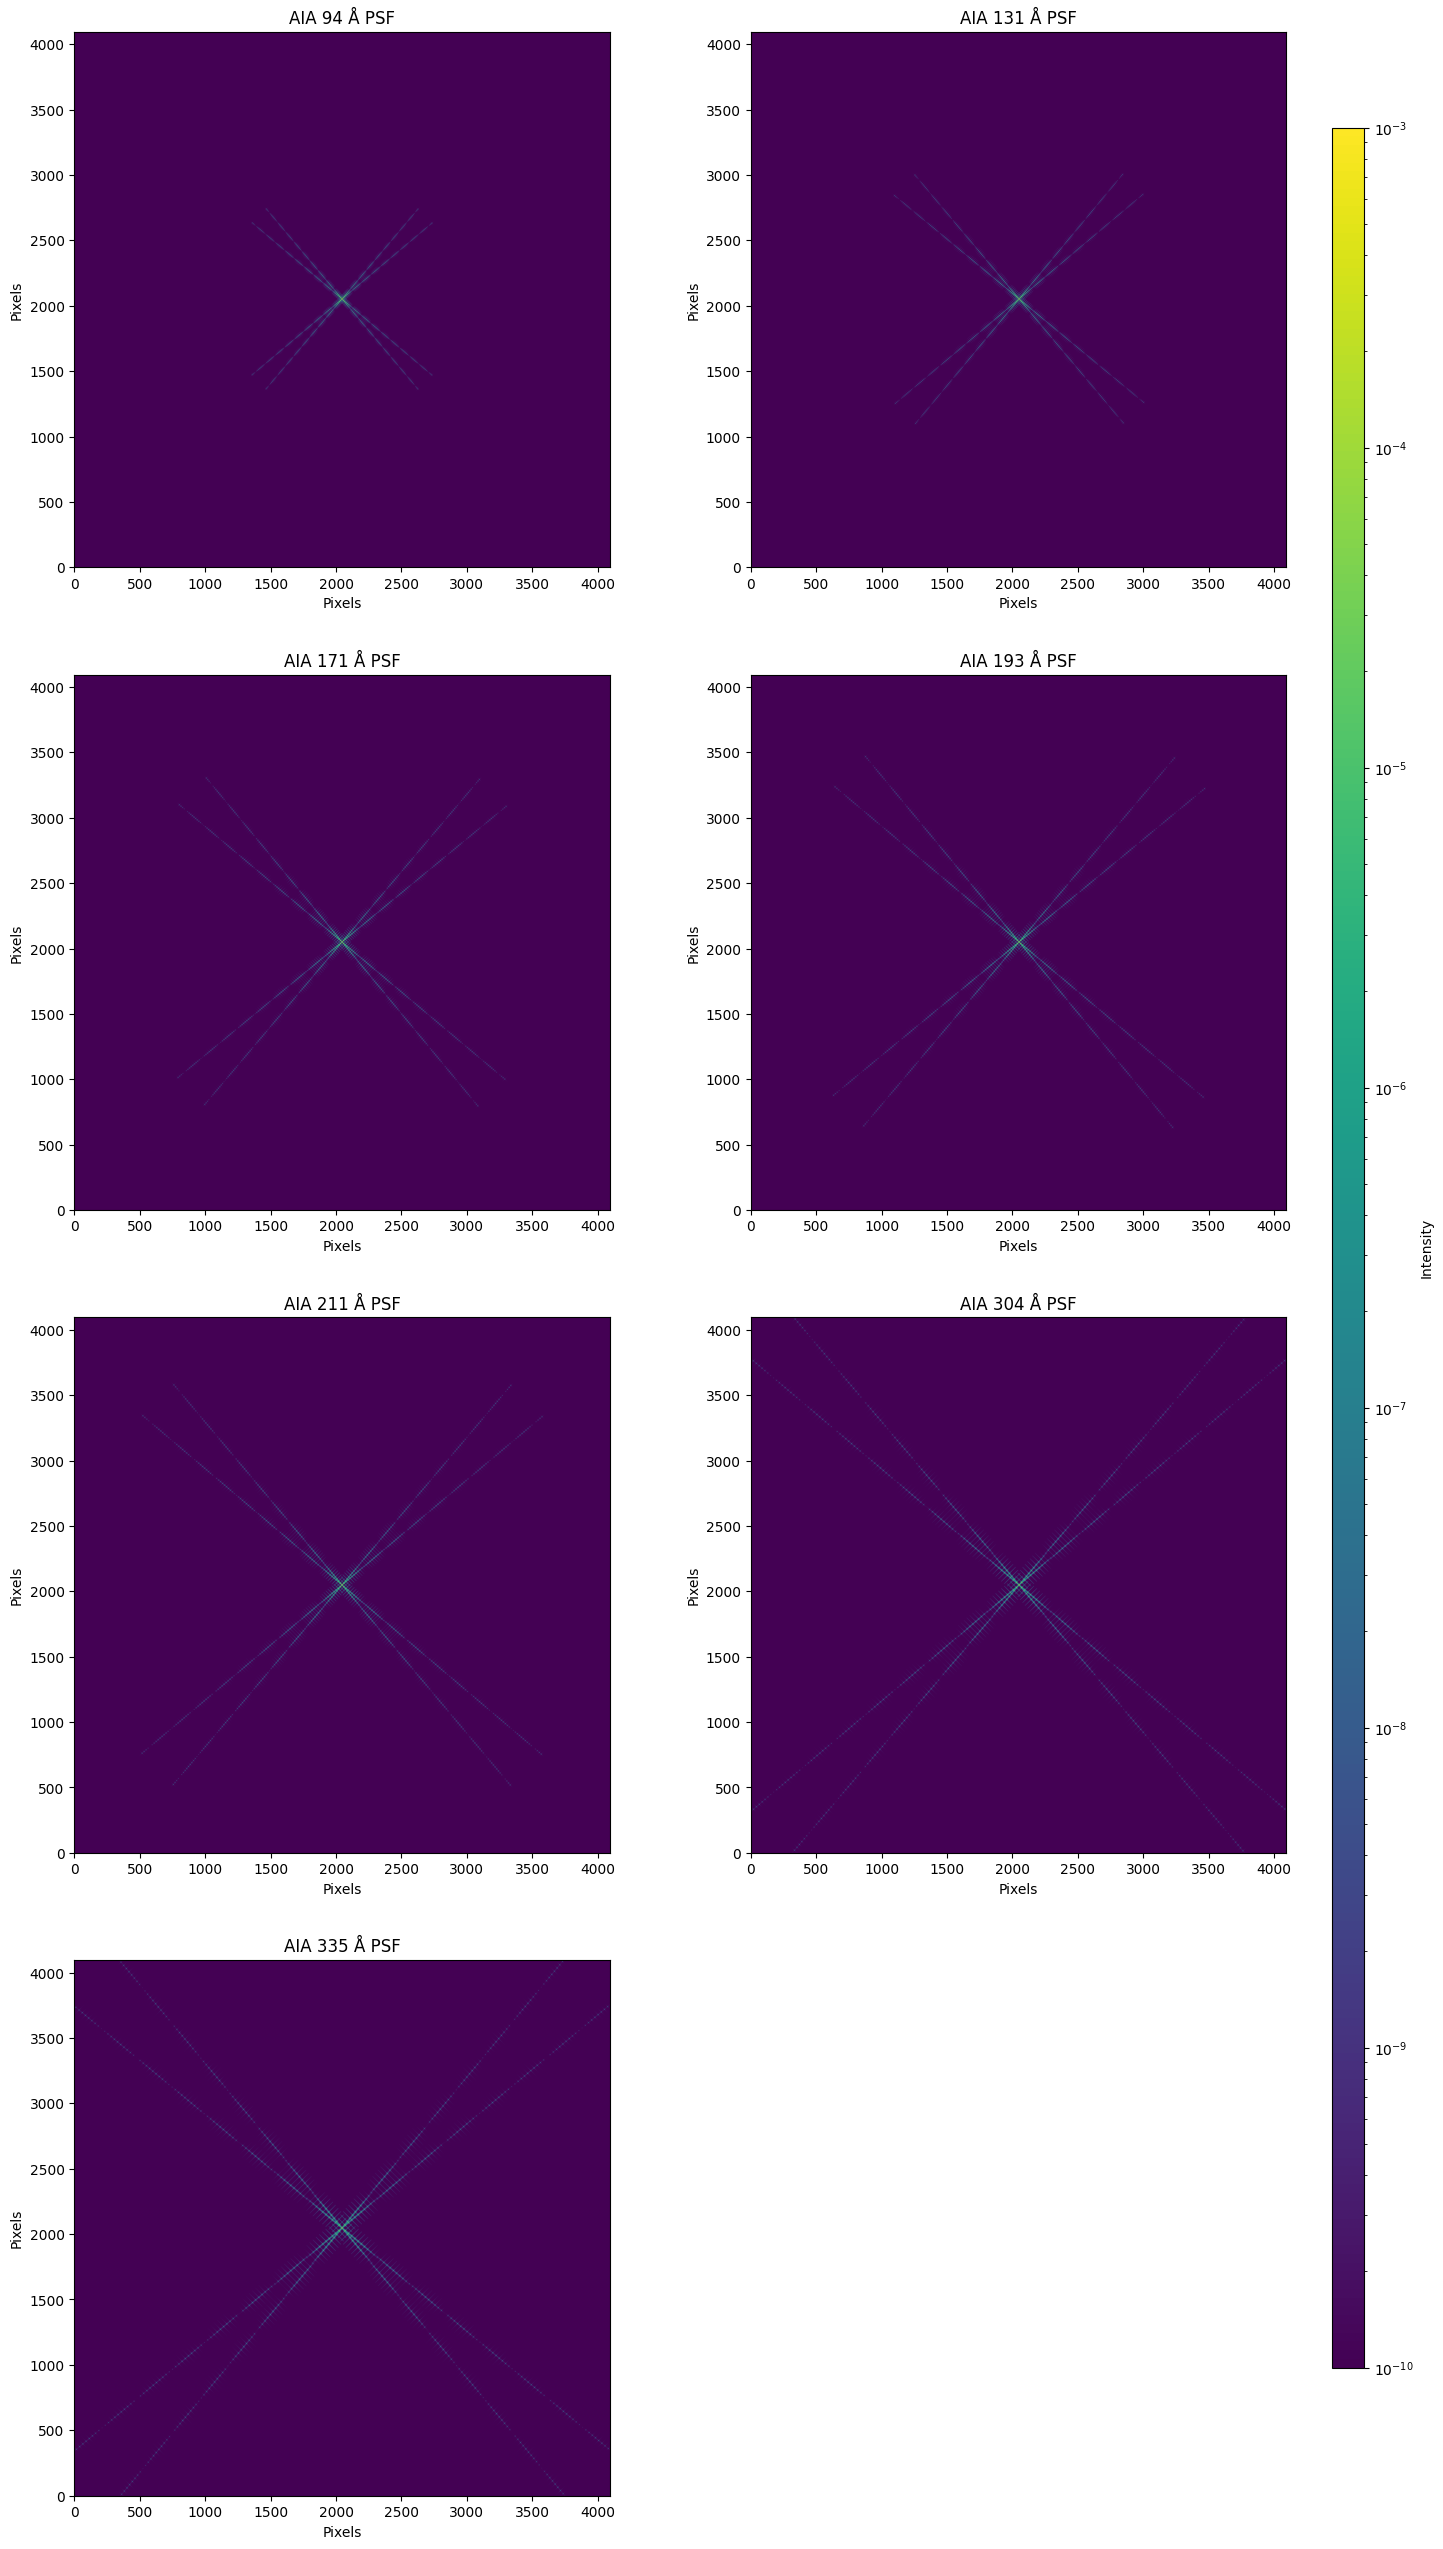

In [16]:
n_cols = 2
n_rows = int(np.ceil(len(wavelength_psfs) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 8 * n_rows))
axes = np.atleast_1d(axes).ravel()

im_list = []
for ax, (wavelength, psf) in zip(axes, wavelength_psfs.items()):
    im = ax.imshow(
        psf,
        norm=colors.LogNorm(vmin=1e-10, vmax=1e-3),
        origin="lower",
        cmap="viridis",
    )
    ax.set_title(f"AIA {wavelength.value:.0f} Å PSF")
    ax.set_xlabel("Pixels")
    ax.set_ylabel("Pixels")
    im_list.append(im)

# Add a single colorbar for all subplots
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(im_list[0], cax=cbar_ax, label="Intensity")

# Hide any unused subplots
for ax in axes[len(wavelength_psfs) :]:
    ax.axis("off")

fig.subplots_adjust(right=0.9)

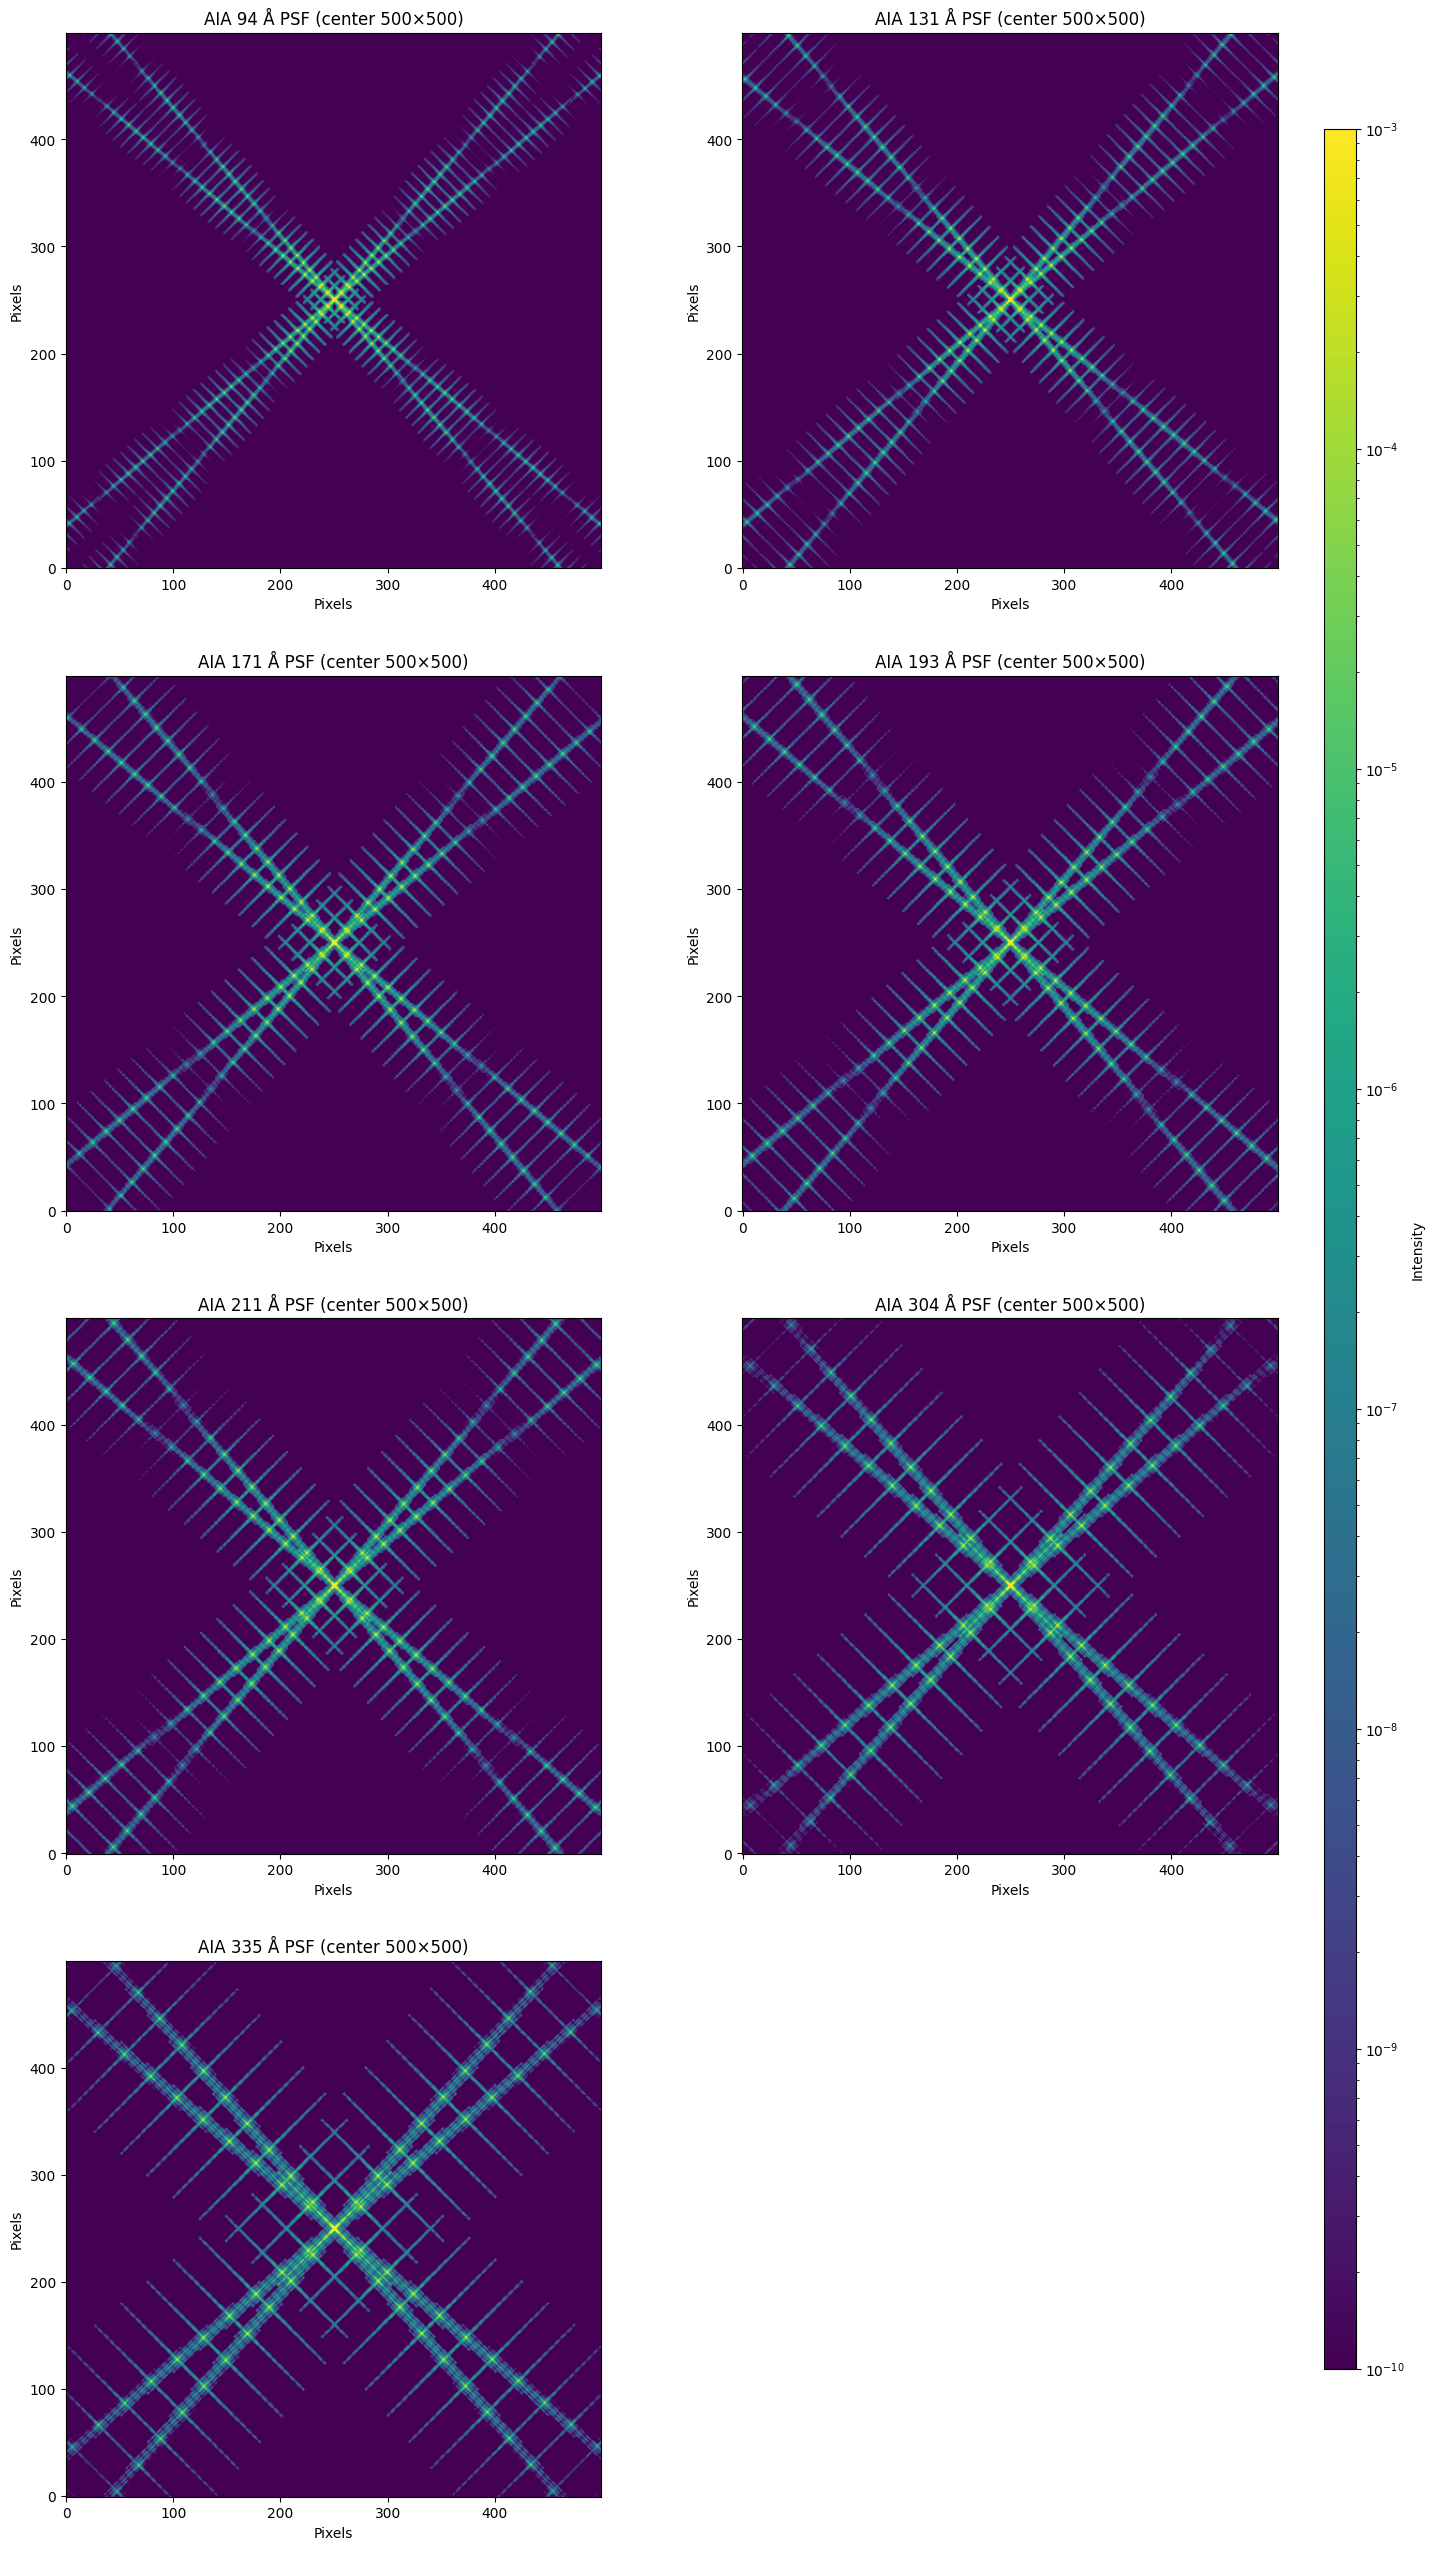

In [17]:
n_cols = 2
n_rows = int(np.ceil(len(wavelength_psfs) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 8 * n_rows))
axes = np.atleast_1d(axes).ravel()
fov = 500

im_list = []
for ax, (wavelength, psf) in zip(axes, wavelength_psfs.items()):
    lc_x, lc_y = psf.shape[0] // 2 - fov // 2, psf.shape[1] // 2 - fov // 2
    im = ax.imshow(
        psf[lc_x : lc_x + fov, lc_y : lc_y + fov],
        norm=colors.LogNorm(vmin=1e-10, vmax=1e-3),
        origin="lower",
        cmap="viridis",
    )
    ax.set_title(f"AIA {wavelength.value:.0f} Å PSF (center {fov}×{fov})")
    ax.set_xlabel("Pixels")
    ax.set_ylabel("Pixels")
    im_list.append(im)

# Add a single colorbar for all subplots
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(im_list[0], cax=cbar_ax, label="Intensity")

# Hide any unused subplots
for ax in axes[len(wavelength_psfs) :]:
    ax.axis("off")

fig.subplots_adjust(right=0.9)

In [18]:
# Deconvolve the AIA Map with the PSF for the 171 Å Wavelength
psf = wavelength_psfs[171 * u.angstrom]
aia_map_deconvolved = aiapy.psf.deconvolve(aia_map, psf=psf)

# 8.0s /wavelength/timeslice
# Test that the results are the same between a CPU and GPU device.
# We don't want to loose precision when we de-convolve but we also don't want to use too much more space.

Observatory,SDO
Instrument,AIA 3
Detector,AIA
Measurement,171.0 Angstrom
Wavelength,171.0 Angstrom
Observation Date,2017-09-10 20:00:09
Exposure Time,2.000169 s
Dimension,[4096. 4096.] pix
Coordinate System,helioprojective
Scale,[0.599489 0.599489] arcsec / pix
Reference Pixel,[2052.300049 2048.280029] pix

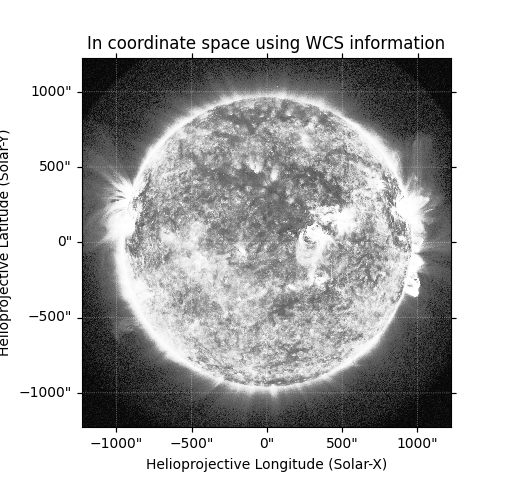
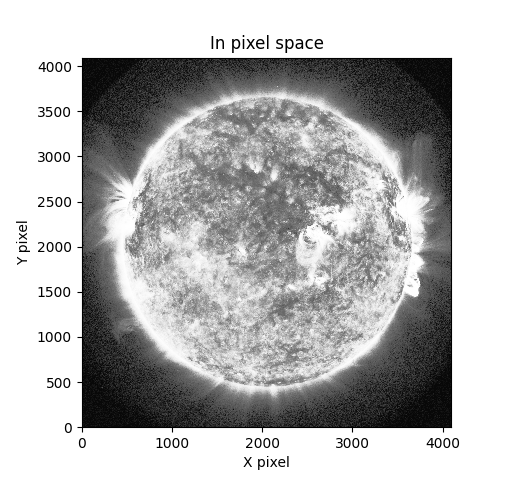
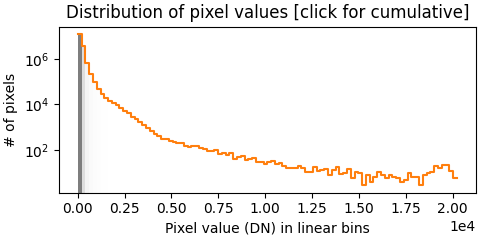
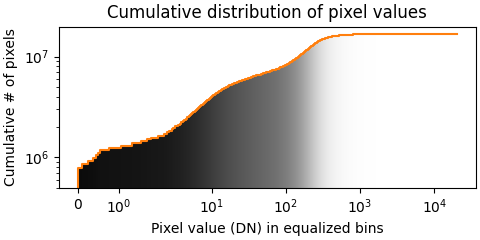

In [19]:
aia_map_deconvolved

In [20]:
aia_map_deconvolved.data.dtype

dtype('float64')

In [21]:
orig_name = Path(files[0]).name
# For now just add a note in the filename that this is a deconvolved file. We can add more metadata later.
deconvolved_name = orig_name.replace("lev1", "lev1d")

# For now use the default SunPy map save method. We can add more metadata later.
# We may also want to modify how we save the deconvolved image to FITS to optimize the file size.
# For example, we may want to use a different compression method or a different data type for the deconvolved image.
aia_map_deconvolved.save(local_test_files_dir / deconvolved_name, overwrite=True)

2026-09-04 10:54:18 - astropy - WARNING: VerifyWarning: Invalid 'BLANK' keyword in header.  The 'BLANK' keyword is only applicable to integer data, and will be ignored in this HDU.


In [22]:
# Analyze the Deconvolved L1 AIA File Size
size = (local_test_files_dir / deconvolved_name).stat().st_size
print(f"Size of the deconvolved L1 AIA file: {size / 1024**2:.2f} MB")

# 10x bigger than the original
# Goes from Int16 to Float64

Size of the deconvolved L1 AIA file: 128.02 MB


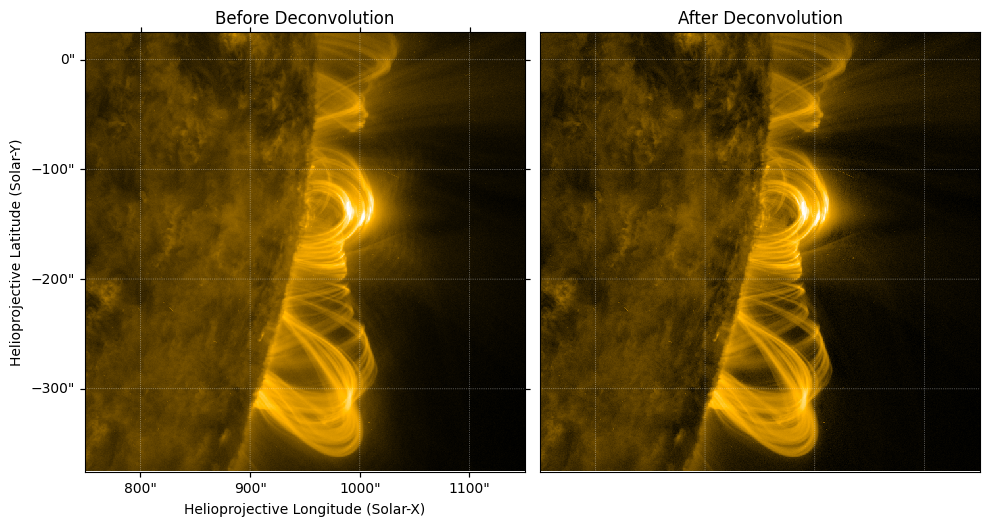

In [23]:
bottom_left = SkyCoord(750, -375, unit="arcsec", frame=aia_map.coordinate_frame)
fov = {"width": 400 * u.arcsec, "height": 400 * u.arcsec}

aia_map_sub = aia_map.submap(bottom_left, **fov)
aia_map_deconvolved_sub = aia_map_deconvolved.submap(bottom_left, **fov)

fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(121, projection=aia_map_sub)
aia_map_sub.plot(axes=ax1, title="Before Deconvolution")
ax2 = fig.add_subplot(122, projection=aia_map_deconvolved_sub)
aia_map_deconvolved_sub.plot(axes=ax2, title="After Deconvolution")
# Just remove the ticks and labels
lon = ax2.coords[0]
lat = ax2.coords[1]
lon.set_ticks_visible(False)
lon.set_ticklabel_visible(False)
lat.set_ticks_visible(False)
lat.set_ticklabel_visible(False)
lon.set_axislabel("")
lat.set_axislabel("")
fig.tight_layout()

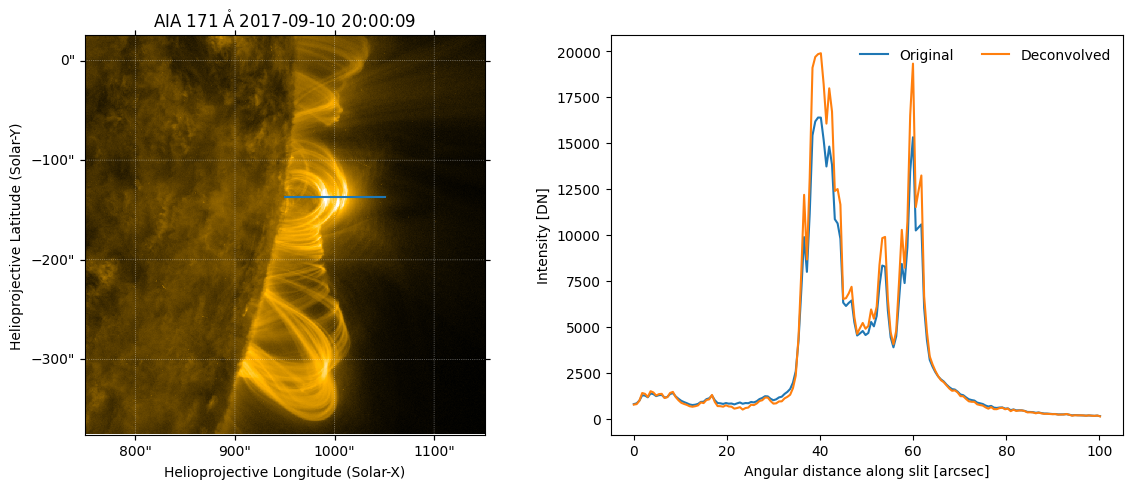

In [24]:
line_coords = SkyCoord(
    [950, 1050],
    [-137, -137],
    unit=(u.arcsec, u.arcsec),
    frame=aia_map_sub.coordinate_frame,
)
intensity_coords = sunpy.map.pixelate_coord_path(aia_map_sub, line_coords)
before_intensity = sunpy.map.sample_at_coords(aia_map_sub, intensity_coords)
after_intensity = sunpy.map.sample_at_coords(aia_map_deconvolved_sub, intensity_coords)
angular_separation = intensity_coords.separation(intensity_coords[0]).to(u.arcsec)

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121, projection=aia_map_sub)
aia_map_sub.plot(axes=ax1)
ax1.plot_coord(intensity_coords)

ax2 = fig.add_subplot(122)
ax2.plot(angular_separation, before_intensity, label="Original")
ax2.plot(angular_separation, after_intensity, label="Deconvolved")
ax2.set_xlabel("Angular distance along slit [arcsec]")
ax2.set_ylabel(f"Intensity [{aia_map_sub.unit}]")
ax2.legend(loc="best", ncol=2, frameon=False)
fig.tight_layout()

plt.show()